# 3. Classification: dropout, enrolled or graduate

Five models compared on the same stratified test set. Hyperparameters for kNN and SVM are tuned with 5-fold cross-validation on the training set, optimising macro F1.

Note: the features include second-semester performance, so this predicts the final outcome at the end of the first year, not at enrolment.

In [1]:
import sys
sys.path.append("../src")
from pathlib import Path

FIGURES = Path("../figures")
FIGURES.mkdir(exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, accuracy_score

X_train = pd.read_csv("../data/X_train.csv")
X_test = pd.read_csv("../data/X_test.csv")
y_train = pd.read_csv("../data/y_train.csv").squeeze()
y_test = pd.read_csv("../data/y_test.csv").squeeze()

## Scaling

Standardised features for the distance- and gradient-based models; the scaler is fit on the training set.

In [2]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_train.columns)

## Logistic regression

              precision    recall  f1-score   support

     Dropout       0.75      0.73      0.74       284
    Enrolled       0.49      0.35      0.41       159
    Graduate       0.81      0.92      0.86       442

    accuracy                           0.75       885
   macro avg       0.69      0.66      0.67       885
weighted avg       0.74      0.75      0.74       885



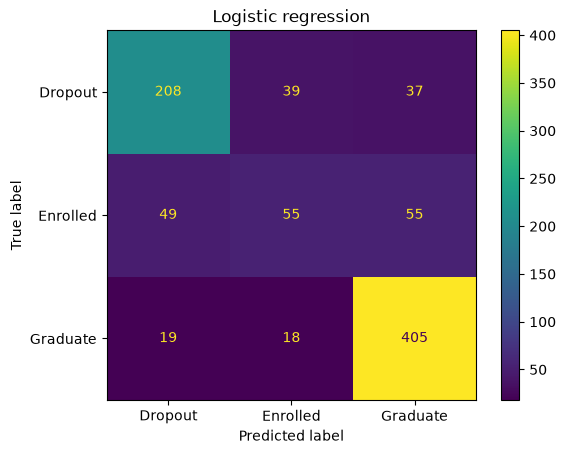

In [3]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

print(classification_report(y_test, y_pred_lr))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr)
plt.title("Logistic regression")
plt.savefig(FIGURES / "confusion_matrix_logreg.png", dpi=120, bbox_inches="tight")
plt.show()

## Random forest

              precision    recall  f1-score   support

     Dropout       0.81      0.79      0.80       284
    Enrolled       0.62      0.36      0.45       159
    Graduate       0.81      0.94      0.87       442

    accuracy                           0.79       885
   macro avg       0.75      0.70      0.71       885
weighted avg       0.78      0.79      0.77       885



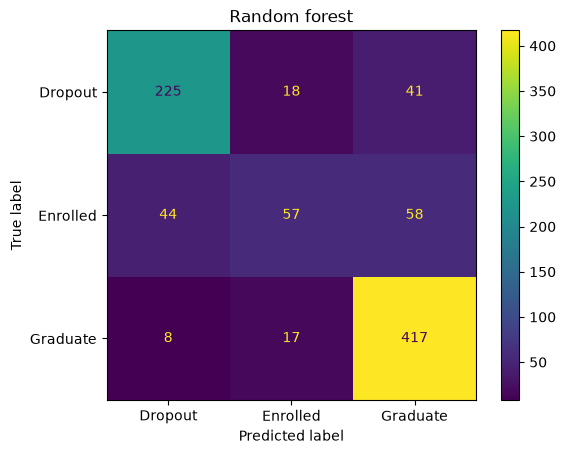

In [4]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print(classification_report(y_test, y_pred_rf))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf)
plt.title("Random forest")
plt.show()

## k-nearest neighbours

best k: {'n_neighbors': 5}
best CV macro F1: 0.5809
              precision    recall  f1-score   support

     Dropout       0.70      0.60      0.65       284
    Enrolled       0.36      0.25      0.30       159
    Graduate       0.72      0.86      0.78       442

    accuracy                           0.67       885
   macro avg       0.59      0.57      0.57       885
weighted avg       0.65      0.67      0.65       885



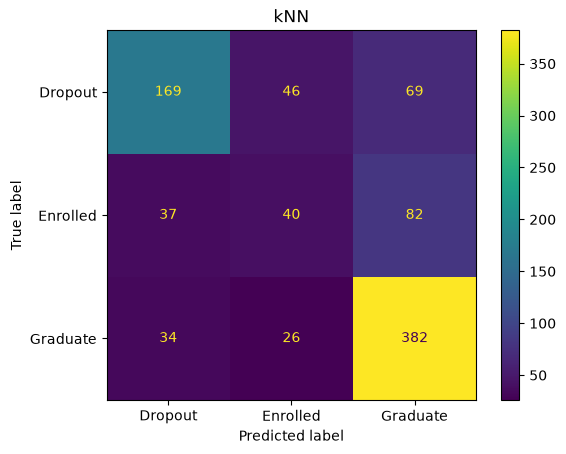

In [5]:
grid_knn = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": [3, 5, 7, 9, 11, 15, 21]},
                        cv=5, scoring="f1_macro")
grid_knn.fit(X_train_scaled, y_train)

print(f"best k: {grid_knn.best_params_}")
print(f"best CV macro F1: {grid_knn.best_score_:.4f}")

y_pred_knn = grid_knn.predict(X_test_scaled)
print(classification_report(y_test, y_pred_knn))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn)
plt.title("kNN")
plt.show()

## Support vector machine (RBF kernel)

best parameters: {'C': 1, 'gamma': 'auto'}
best CV macro F1: 0.6878
              precision    recall  f1-score   support

     Dropout       0.82      0.71      0.76       284
    Enrolled       0.54      0.33      0.41       159
    Graduate       0.78      0.95      0.85       442

    accuracy                           0.76       885
   macro avg       0.71      0.66      0.68       885
weighted avg       0.75      0.76      0.74       885



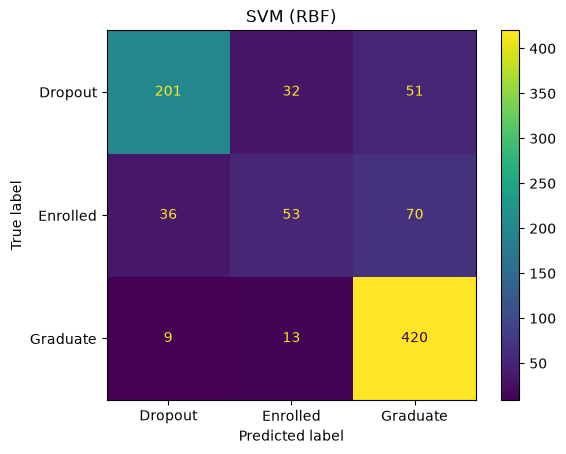

In [6]:
grid_svm = GridSearchCV(SVC(kernel="rbf", random_state=42),
                        {"C": [0.1, 1, 10], "gamma": ["scale", "auto"]},
                        cv=5, scoring="f1_macro")
grid_svm.fit(X_train_scaled, y_train)

print(f"best parameters: {grid_svm.best_params_}")
print(f"best CV macro F1: {grid_svm.best_score_:.4f}")

y_pred_svm = grid_svm.predict(X_test_scaled)
print(classification_report(y_test, y_pred_svm))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svm)
plt.title("SVM (RBF)")
plt.show()

## Multilayer perceptron

              precision    recall  f1-score   support

     Dropout       0.81      0.75      0.78       284
    Enrolled       0.50      0.41      0.45       159
    Graduate       0.81      0.90      0.85       442

    accuracy                           0.76       885
   macro avg       0.71      0.69      0.69       885
weighted avg       0.75      0.76      0.76       885



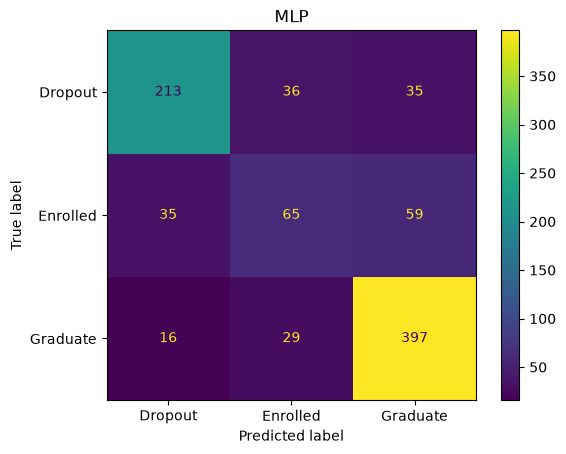

In [7]:
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)

mlp = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42, early_stopping=True)
mlp.fit(X_train_scaled, y_train_enc)
y_pred_mlp = le.inverse_transform(mlp.predict(X_test_scaled))

print(classification_report(y_test, y_pred_mlp))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_mlp)
plt.title("MLP")
plt.show()

## Model comparison

In [8]:
predictions = {
    "Logistic regression": y_pred_lr,
    "Random forest": y_pred_rf,
    "kNN": y_pred_knn,
    "SVM (RBF)": y_pred_svm,
    "MLP": y_pred_mlp,
}

results = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "Weighted F1": f1_score(y_test, pred, average="weighted"),
        "F1 enrolled": f1_score(y_test, pred, labels=["Enrolled"], average=None)[0],
    }
    for name, pred in predictions.items()
]).sort_values("Macro F1", ascending=False)

print(results.round(3).to_string(index=False))

              Model  Accuracy  Macro F1  Weighted F1  F1 enrolled
      Random forest     0.790     0.709        0.774        0.454
                MLP     0.763     0.693        0.755        0.450
          SVM (RBF)     0.762     0.675        0.744        0.412
Logistic regression     0.755     0.670        0.742        0.406
                kNN     0.668     0.575        0.651        0.295


The weakest class for every model is `Enrolled`: it is the smallest class and sits between the other two outcomes, so it is often confused with both.

## Cross-validated comparison

A single test split of 885 students is noisy, so the models are also compared with stratified 5-fold cross-validation on the training set. Scaling is fitted inside each fold, and kNN and SVM use the hyperparameters selected above.

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv_models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Random forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "kNN": make_pipeline(StandardScaler(), KNeighborsClassifier(**grid_knn.best_params_)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=42, **grid_svm.best_params_)),
    "MLP": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500,
                                                        random_state=42, early_stopping=True)),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = pd.DataFrame([
    {"Model": name, "CV macro F1 (mean)": s.mean(), "CV macro F1 (std)": s.std()}
    for name, s in ((name, cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro"))
                    for name, model in cv_models.items())
]).sort_values("CV macro F1 (mean)", ascending=False)

print(cv_results.round(3).to_string(index=False))

              Model  CV macro F1 (mean)  CV macro F1 (std)
Logistic regression               0.698              0.015
      Random forest               0.686              0.018
                MLP               0.686              0.028
          SVM (RBF)               0.679              0.014
                kNN               0.594              0.019


## Feature importance (random forest)

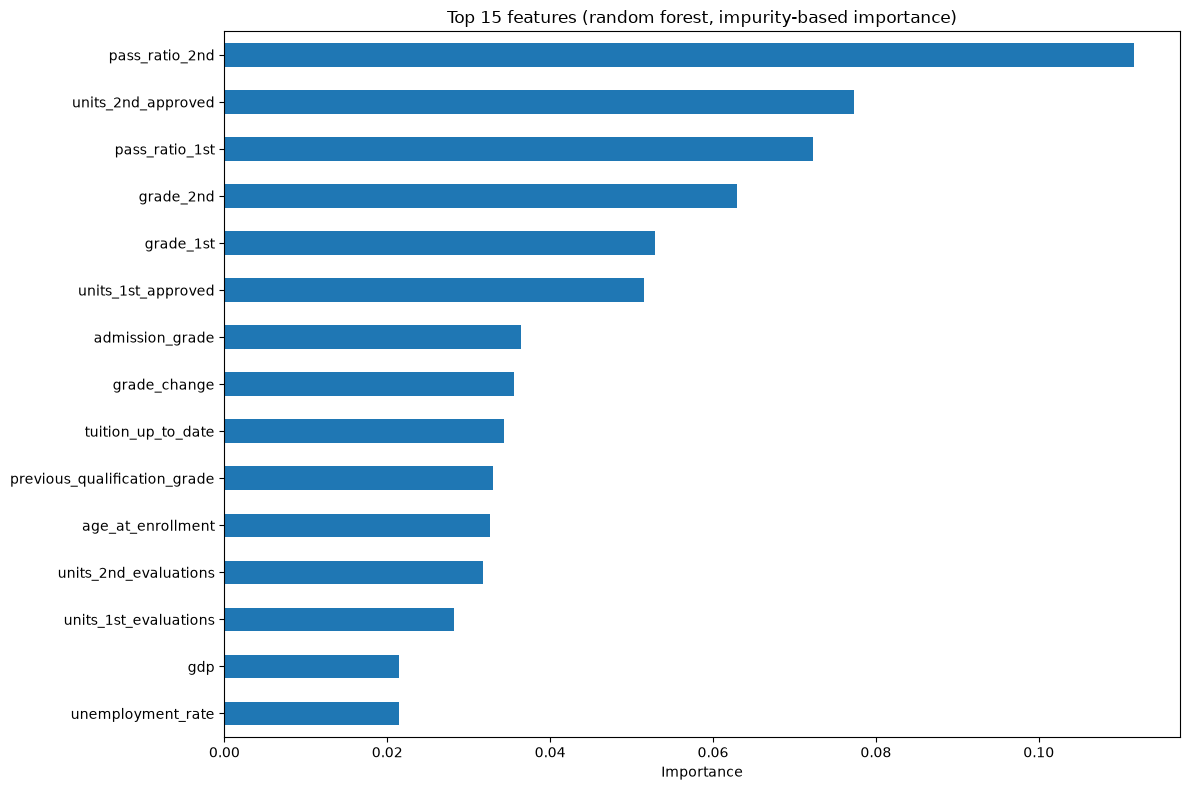

In [10]:
feat_imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(12, 8))
feat_imp.head(15).plot(kind="barh")
plt.title("Top 15 features (random forest, impurity-based importance)")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURES / "feature_importance_classification.png", dpi=120, bbox_inches="tight")
plt.show()